# Tutorial 5: error mitigation (Qiskit)

<!-- BEGIN SOLUTION (remove) -->
> **This version includes the solutions.** Try each exercise yourself before reading its solution.

<!-- END SOLUTION -->
*Near-term Quantum Computing 2026-2027, tutorial 5.*

In Lecture 5, we met two methods of error mitigation: zero-noise extrapolation (ZNE) and symmetry
verification. In this tutorial, we run circuits on a model of a real device, IQM's 20-qubit Garnet,
and we check two pieces of mitigation code that look as if they work: ZNE of the energy of
Tutorial 4, and symmetry verification of the light cone of Lecture 3.

In this tutorial you will learn to:

1. compile and run circuits on a model of a device, and choose the qubits they run on;
2. read the code of a mitigation method, and find where it does not do what the method needs;
3. judge a mitigated result: how much bias it removes, and what it costs in standard error.

**How this tutorial works.** This tutorial has one block.

- **Part A** (about 20 minutes): we code together. Type the code yourself in the empty cells.
- **Part B**: two exercises, started in class and finished at home, alone or in pairs. Both ask you
  to find the mistakes in given code, as Exercise 3 of Tutorial 4.

**Conventions**, as in Tutorial 4: the TFIM on an open chain of $n = 4$ qubits,
$H = -J\sum_i Z_iZ_{i+1} - h\sum_i X_i$, with $J = 1$ and $h = 0.5$. An energy estimate with
"$N$ shots" uses $N$ shots in each of the two measurement settings. The qubits of a circuit are
numbered from 0, as in Qiskit.

Documentation: [Qiskit API reference](https://quantum.cloud.ibm.com/docs/en/api/qiskit),
[`transpile`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/compiler#transpile), and IQM's
[Qiskit user guide](https://docs.meetiqm.com/iqm-client/user_guide_qiskit.html), which describes
the device models ("fake backends").

## Setup

In Google Colab, run the next cell first to install the packages. If you work on your own
computer, install the same packages in your Python environment instead. The model of Garnet comes
with `iqm-client`, which we install without its `[qiskit]` extra: the extra would replace Qiskit
by an older version.

In [1]:
%pip install -q "qiskit~=2.5.2" "qiskit-aer~=0.18.0" "iqm-client==36.0.0" pylatexenc

import sys
import IPython.core.display
# Colab has an older IPython than iqm-client expects; this line lets iqm-client be imported there
sys.modules.setdefault("IPython.core.display_functions", IPython.core.display)

Note: you may need to restart the kernel to use updated packages.


<module 'IPython.core.display_functions' from '/Users/stefano/.venvs/ntqc-tutorials/lib/python3.12/site-packages/IPython/core/display_functions.py'>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp

J, h = 1.0, 0.5

The next cell is given: functions of Tutorials 3 and 4 that we reuse. `tfim(n_qubits, J, h)` builds
the Hamiltonian, `signs(bitstring)` turns the bits of one shot into signs $\pm 1$, and
`hva_ansatz(n_qubits, n_layers)` is the HVA of Tutorial 4.

In [3]:
def tfim(n_qubits, J, h):
    """The TFIM on an open chain of n_qubits qubits, as a SparsePauliOp."""
    terms = []
    for i in range(n_qubits - 1):                      # bonds
        terms.append(("ZZ", [i, i + 1], -J))
    for i in range(n_qubits):                          # fields
        terms.append(("X", [i], -h))
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n_qubits)


def signs(bitstring):
    """The outcomes of one shot as signs: signs(bitstring)[q] is +1 or -1 for qubit q."""
    return [1 - 2 * int(b) for b in bitstring[::-1]]   # reversed: Qiskit writes qubit 0 last


def hva_ansatz(n_qubits, n_layers):
    """The HVA with n_layers layers on n_qubits qubits; its parameters are (γ_1, β_1, ..., γ_p, β_p)."""
    theta = ParameterVector("theta", 2 * n_layers)
    circuit = QuantumCircuit(n_qubits)
    circuit.h(range(n_qubits))                          # |+...+>
    for k in range(n_layers):
        for i in range(0, n_qubits - 1, 2):             # bonds (0,1), (2,3), ...
            circuit.rzz(theta[2 * k], i, i + 1)
        for i in range(1, n_qubits - 1, 2):             # bonds (1,2), (3,4), ...
            circuit.rzz(theta[2 * k], i, i + 1)
        for i in range(n_qubits):                       # fields
            circuit.rx(theta[2 * k + 1], i)
    return circuit

Our circuit, `state_circuit`, is the HVA with 3 layers at the angles that COBYLA found with exact
energies in Tutorial 4, A2. Without noise, its energy is 0.003 above $E_0$; in Tutorial 4,
Exercise 4, depolarising noise of 0.1% per `r` gate and 0.5% per CZ raised it to 0.28 above $E_0$.

In [4]:
n_qubits = 4
hamiltonian = tfim(n_qubits, J, h)
E0 = np.linalg.eigvalsh(hamiltonian.to_matrix())[0]
angles = [-0.655, -1.331, -1.291, -1.137, -1.264, -0.574]   # found in Tutorial 4, A2
state_circuit = hva_ansatz(n_qubits, 3).assign_parameters(angles)
exact_energy = Statevector(state_circuit).expectation_value(hamiltonian).real
print("E0 =", round(E0, 4), "  exact E - E0 =", round(exact_energy - E0, 4))
print(state_circuit.draw(fold=-1))

E0 = -3.427   exact E - E0 = 0.0032
     ┌───┐             ┌────────────┐                           ┌────────────┐                           ┌────────────┐              
q_0: ┤ H ├─■───────────┤ Rx(-1.331) ├───────────────■───────────┤ Rx(-1.137) ├───────────────■───────────┤ Rx(-0.574) ├──────────────
     ├───┤ │ZZ(-0.655) └────────────┘┌────────────┐ │ZZ(-1.291) └────────────┘┌────────────┐ │ZZ(-1.264) └────────────┘┌────────────┐
q_1: ┤ H ├─■────────────■────────────┤ Rx(-1.331) ├─■────────────■────────────┤ Rx(-1.137) ├─■────────────■────────────┤ Rx(-0.574) ├
     ├───┤              │ZZ(-0.655)  ├────────────┤              │ZZ(-1.291)  ├────────────┤              │ZZ(-1.264)  ├────────────┤
q_2: ┤ H ├─■────────────■────────────┤ Rx(-1.331) ├─■────────────■────────────┤ Rx(-1.137) ├─■────────────■────────────┤ Rx(-0.574) ├
     ├───┤ │ZZ(-0.655) ┌────────────┐└────────────┘ │ZZ(-1.291) ┌────────────┐└────────────┘ │ZZ(-1.264) ┌────────────┐└────────────┘
q_3: ┤ H ├─■───────────┤ R

## Part A: coding together

### A1. A model of a device

Garnet is IQM's superconducting device with 20 qubits on a square lattice (notes, figure
["Choosing the qubits on IQM's Garnet"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#fig-qubit-selection)). `iqm-client` contains a model
of it, `IQMFakeGarnet`. It is a *backend*: an object that compiles and runs circuits as the device
does, here simulated on your computer. It knows the device's qubits, its native gates, the pairs
of qubits that can run a CZ (the *coupling map*), and a noise model with the error rates of one
past calibration of the device: gate errors, relaxation during the gates, and readout errors.

![Garnet's coupling map, with the error probability of each CZ, and the best, worst and default layouts of the chain of Tutorial 4 (figure from the notes of Lecture 5)](https://stefanopolla.com/course-testing/figures/qubit-selection.svg)

In the figure from the notes, each circle is a qubit, QB1 to QB20, and each diamond is a pair that can run a CZ,
with its error probability. The three coloured paths are layouts of the 4-qubit chain of Tutorial 4;
below the circuit is its circuit fault rate $\lambda$ on each of them.

Create the backend, `garnet = IQMFakeGarnet()`, and print its number of qubits
(`garnet.num_qubits`), its native operations (`garnet.operation_names`) and its coupling map
(`garnet.coupling_map`). Qiskit numbers the qubits from 0, like the positions in a Python list,
while IQM names them from 1, QB1 to QB20, as in the figure and on IQM Resonance: Qiskit's qubit 12
is QB13. The backend converts between the two: `garnet.qubit_name_to_index("QB13")` is 12, and
`garnet.index_to_qubit_name(12)` is `"QB13"`.

In [5]:
from iqm.qiskit_iqm.fake_backends.fake_garnet import IQMFakeGarnet

# garnet: the model of Garnet; print its number of qubits, native operations and coupling map
# BEGIN SOLUTION
garnet = IQMFakeGarnet()
print("qubits:", garnet.num_qubits)
print("native operations:", garnet.operation_names)
print("coupling map:", garnet.coupling_map)
# END SOLUTION

qubits: 20
native operations: ['id', 'delay', 'measure', 'r', 'cz']
coupling map: [[0, 1], [0, 3], [1, 4], [2, 3], [3, 4], [4, 5], [5, 6], [7, 2], [7, 8], [7, 12], [8, 3], [8, 9], [8, 13], [9, 4], [9, 10], [9, 14], [10, 5], [10, 11], [11, 6], [12, 13], [13, 14], [15, 10], [15, 14], [15, 16], [15, 19], [16, 11], [17, 13], [17, 18], [18, 14], [18, 19]]


The native gates are the `r` gate (PRX, Tutorial 2) and the CZ; `delay` and `id` make a qubit
wait. Check that the printed coupling map matches the figure: for example, the chain QB13, QB14,
QB18, QB19 of the figure is the pairs [12, 13], [17, 13] and [17, 18] of the list.

### A2. Compiling and running

`transpile(circuit, backend=garnet, optimization_level=1)` compiles a circuit for Garnet, into its
native gates and onto its qubits; as in Tutorials 3 and 4, `optimization_level=1` merges
neighbouring single-qubit gates. The compiler chooses a *layout*, the physical qubit that plays
each qubit of the circuit, and adds SWAP gates where the circuit needs a CZ between qubits that
are not coupled.
`garnet.run(native, shots=1000)` then runs the compiled circuit with Garnet's noise, as
`simulator.run` did in Tutorial 1. The bit strings of the counts give the qubits of *your* circuit,
in the usual order (qubit 0 last), whichever physical qubits ran them.

Compile `circuit`, the circuit of Tutorial 4 with its measurements. Print its gate counts
(`native.count_ops()`) and the physical qubits it runs on (`native.layout.final_index_layout()`),
then run it with 1000 shots and print the counts.

In [6]:
circuit = state_circuit.copy()
circuit.measure_all()
# native: `circuit` compiled for garnet; print its gate counts and physical qubits, then run it
# BEGIN SOLUTION
native = transpile(circuit, backend=garnet, optimization_level=1)
print(native.count_ops())
print("physical qubits:", native.layout.final_index_layout())
counts = garnet.run(native, shots=1000).result().get_counts()
print(counts)
# END SOLUTION

OrderedDict({'r': 27, 'cz': 18, 'measure': 4, 'barrier': 1})
physical qubits: [5, 6, 11, 16]
{'1010': 10, '0011': 20, '0001': 42, '0101': 7, '0110': 26, '1011': 20, '1110': 52, '0100': 18, '1100': 21, '1000': 47, '1001': 13, '0111': 39, '1111': 319, '1101': 25, '0010': 19, '0000': 322}


The compiler picks a layout that follows the coupling map, but it does not know which qubits are
best: the model, like the device, gives it no error rates (notes, section
["Choosing the qubits"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-qubit-selection)). To choose the qubits ourselves, we fix the
layout: `transpile(..., initial_layout=[12, 13, 17, 18])` puts qubit 0 of the circuit on the
physical qubit 12 (QB13), qubit 1 on 13 (QB14), and so on. On this chain, QB13, QB14, QB18, QB19,
the CZs of our circuit have the lowest error rates (notes, same figure).

Build the layout `chain` from the names of the figure, with `garnet.qubit_name_to_index`. Then
compile `circuit` on `chain`, and on QB1, QB2, QB3, QB4, and print the gate counts. The circuit has 9 bond gates $R_{ZZ}$, of 2 CZs each: compare the number of CZs with 18.

In [7]:
# chain: the Qiskit numbers of QB13, QB14, QB18, QB19; first: those of QB1, QB2, QB3, QB4.
# Compile `circuit` with each of the two layouts, and print the gate counts
# BEGIN SOLUTION
chain = []
for name in ["QB13", "QB14", "QB18", "QB19"]:
    chain.append(garnet.qubit_name_to_index(name))
first = []
for name in ["QB1", "QB2", "QB3", "QB4"]:
    first.append(garnet.qubit_name_to_index(name))
print("chain:", chain, "  first:", first)
native_chain = transpile(circuit, backend=garnet, optimization_level=1, initial_layout=chain)
print("QB13, QB14, QB18, QB19:", native_chain.count_ops())
native_first = transpile(circuit, backend=garnet, optimization_level=1, initial_layout=first)
print("QB1, QB2, QB3, QB4:    ", native_first.count_ops())
# END SOLUTION

chain: [12, 13, 17, 18]   first: [0, 1, 2, 3]
QB13, QB14, QB18, QB19: OrderedDict({'r': 27, 'cz': 18, 'measure': 4, 'barrier': 1})
QB1, QB2, QB3, QB4:     OrderedDict({'r': 38, 'cz': 24, 'measure': 4, 'barrier': 1})


On the chain, every bond gate acts on coupled qubits, so the compiled circuit has
$9 \times 2 = 18$ CZs, as without a device. On QB1 to QB4, QB2 and QB3 are not coupled, so the
compiler adds two SWAP gates, which exchange the states of two coupled qubits, of 3 CZs each:
$18 + 6 = 24$ CZs. More CZs mean more noise: after compiling on a device, check the number of CZs.

### A3. The energy on Garnet

The given function `garnet_energy` is `measure_energy` of Tutorial 4 for Garnet: it compiles the
circuit of each setting with a fixed layout, and runs it on `garnet`. It can also mitigate the
readout errors (notes, section ["Mitigating readout errors"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-readout-mitigation)):

- `readout_errors(layout)` reads $e_0 = p(1\mid 0)$ and $e_1 = p(0\mid 1)$ of each physical qubit
  of the layout from Garnet's calibration data;
- `group_values`, the function of Tutorial 3, now replaces the sign $s = \pm 1$ of each qubit in
  each shot by $(s - (e_1 - e_0))/(1 - e_0 - e_1)$, the formula of the notes. For independent
  readout errors, the products of these signs average to the noiseless $\langle Z_iZ_{i+1}\rangle$.
  With `mitigate_readout=False`, it uses $e_0 = e_1 = 0$, which changes nothing.

Complete `garnet_energy` with the two lines that compile `circuit` on `layout` and run it.

In [8]:
def readout_errors(layout):
    """Arrays e0 and e1: p(1|0) and p(0|1) of the physical qubits in `layout`, from Garnet's calibration data."""
    e0, e1 = [], []
    for physical in layout:
        name = garnet.index_to_qubit_name(physical)        # for example "QB13" for qubit 12
        e0.append(garnet.error_profile.readout_errors[name]["0"])
        e1.append(garnet.error_profile.readout_errors[name]["1"])
    return np.array(e0), np.array(e1)


def group_values(counts, setting, J, h, e0, e1):
    """One value per shot: s_Z if setting is "Z", s_X if setting is "X" (Tutorial 3).

    New: the sign of each qubit q is mitigated for its readout errors e0[q] and e1[q]."""
    values = []
    for bitstring, count in counts.items():
        spins = (np.array(signs(bitstring)) - (e1 - e0)) / (1 - e0 - e1)    # mitigated signs
        n_qubits = len(spins)
        if setting == "Z":
            total = 0
            for i in range(n_qubits - 1):
                total += spins[i] * spins[i + 1]
            value = -J * total
        else:
            value = -h * sum(spins)
        values += [value] * count
    return np.array(values)


def garnet_energy(state_circuit, shots, layout, mitigate_readout):
    """Estimate <H> of the TFIM on garnet, with qubit i of the circuit on the physical qubit layout[i].

    Uses `shots` shots in each of the two settings; returns the estimate and its standard error.
    With mitigate_readout=True, the readout errors are mitigated in every shot."""
    n_qubits = state_circuit.num_qubits
    if mitigate_readout:
        e0, e1 = readout_errors(layout)
    else:
        e0, e1 = np.zeros(n_qubits), np.zeros(n_qubits)   # as if there were no readout errors
    energy, variance = 0, 0
    for setting in ["Z", "X"]:
        circuit = state_circuit.copy()
        if setting == "X":
            circuit.h(range(n_qubits))
        circuit.measure_all()
        # native: `circuit` compiled for garnet on `layout`; counts: its counts from `shots` shots
        # BEGIN SOLUTION
        native = transpile(circuit, backend=garnet, optimization_level=1, initial_layout=layout)
        counts = garnet.run(native, shots=shots).result().get_counts()
        # END SOLUTION
        values = group_values(counts, setting, J, h, e0, e1)
        energy += values.mean()
        variance += values.var() / shots
    return energy, np.sqrt(variance)

Estimate the energy of `state_circuit` on the chain [12, 13, 17, 18], with 10 000 shots, without
and with readout mitigation, and print each estimate minus $E_0$ with its standard error.

In [9]:
chain = [12, 13, 17, 18]          # QB13, QB14, QB18, QB19, as in A2
# BEGIN SOLUTION
energy, error = garnet_energy(state_circuit, 10_000, chain, mitigate_readout=False)
print("without readout mitigation: E - E0 =", round(energy - E0, 3), "±", round(error, 3))
energy, error = garnet_energy(state_circuit, 10_000, chain, mitigate_readout=True)
print("with readout mitigation:    E - E0 =", round(energy - E0, 3), "±", round(error, 3))
# END SOLUTION

without readout mitigation: E - E0 = 0.622 ± 0.018
with readout mitigation:    E - E0 = 0.375 ± 0.02


**Think.** In Tutorial 4, the depolarising model raised the energy of this circuit to 0.28 above
$E_0$. Why is it further from $E_0$ on Garnet, and which part of the difference does the readout
mitigation remove?

<!-- BEGIN SOLUTION -->
**Solution.** On Garnet, the energy is about 0.6 above $E_0$ without readout mitigation, and about
0.35 with it. The depolarising model of Tutorial 4 had no readout errors; Garnet's are about 2.5%
per qubit. A wrong bit flips the sign of one qubit, so readout errors shrink each
$\langle Z_iZ_{i+1}\rangle$ by about $(1 - 2e)^2 \approx 0.90$ and each $\langle X_i\rangle$
by $1 - 2e \approx 0.95$, and raise the energy by about 0.27: this part is removed by the readout
mitigation. The rest comes from the gates. On this chain, Garnet's CZs have error probabilities of
0.7% to 1.0% (notes, figure ["Choosing the qubits on IQM's Garnet"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#fig-qubit-selection)),
more than the 0.5% of Tutorial 4, and the qubits relax during the gates. The readout mitigation
has a small price: dividing each sign by $1 - e_0 - e_1 \approx 0.95$ makes the standard error a
few percent larger.
<!-- END SOLUTION -->

### Summary: running on a device model

| Task | Qiskit |
| --- | --- |
| the model of Garnet | `garnet = IQMFakeGarnet()`, from `iqm.qiskit_iqm.fake_backends.fake_garnet` |
| its qubits, native operations and coupled pairs | `garnet.num_qubits`, `garnet.operation_names`, `garnet.coupling_map` |
| compile for it | `native = transpile(circuit, backend=garnet, optimization_level=1)` |
| ... on chosen qubits | `transpile(..., initial_layout=[12, 13, 17, 18])` |
| check the compiled circuit | `native.count_ops()`, `native.layout.final_index_layout()` |
| run it | `garnet.run(native, shots=1000).result().get_counts()` |
| readout errors of a qubit | `garnet.error_profile.readout_errors["QB13"]`: `"0"` is $p(1\mid 0)$, `"1"` is $p(0\mid 1)$ |

## Part B: exercises

Each exercise gives a fully coded mitigation method, and a report that draws conclusions from its
output. The code runs without errors, but it contains **two conceptual mistakes**, which make the
report wrong; the task says where each one is. The mistakes are about what the methods do, not
about Python. For each claim of the report, ask how the number behind it was obtained, and compare
it with what the notes say the method should give. Change and re-run parts of the code to test
your guesses.

The two exercises are independent. Both use `garnet`, from A1, and Exercise 1 also uses
`garnet_energy`, from A3. Every run with shots is
random, so your numbers will differ a little from those quoted in the text.

### Exercise 1: zero-noise extrapolation

The second cell below applies ZNE to the energy of `state_circuit` on Garnet, following the steps
of the notes (section ["Implementing ZNE"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-zne-steps)):

1. compile the circuit into the native gates `r` and `cz`;
2. fold the compiled circuit $U$ into $U(U^\dagger U)^k$, for the noise scale factors
   $c = 2k + 1 = 1, 3, 5$ (notes, section ["Scaling the noise by folding"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-folding));
3. estimate the energy at each $c$ with `garnet_energy`, which compiles the folded circuit again
   on the chain of Part A and runs it, with 10 000 shots;
4. extrapolate to $c = 0$, with the linear model through $c = 1, 3$ and the Richardson model through
   $c = 1, 3, 5$, and compute their standard errors from the standard errors at each $c$ (notes,
   sections ["Extrapolating to zero noise"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-extrapolation) and
   ["The price: amplified shot noise"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-zne-variance)).

The report after the cell draws conclusions from the output. One mistake is in the folding
(`fold`), and one in the energy estimates (the loop over $c$).

**Your task.** (a) Find each mistake, and explain in one or two sentences why it is wrong. (b) Fix
the code (in the empty cell after the report, starting from a copy of the second cell), run it,
and rewrite the report. Compare your result with the example of the notes (figure
["Zero-noise extrapolation of the energy"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#fig-zne)), which used the depolarising model of
Tutorial 4.

In [10]:
# The problem, defined again so that this exercise stands alone (as in Part A)
n_qubits = 4
hamiltonian = tfim(n_qubits, J, h)
E0 = np.linalg.eigvalsh(hamiltonian.to_matrix())[0]
angles = [-0.655, -1.331, -1.291, -1.137, -1.264, -0.574]   # found in Tutorial 4, A2
state_circuit = hva_ansatz(n_qubits, 3).assign_parameters(angles)
chain = [12, 13, 17, 18]                                     # QB13, QB14, QB18, QB19

c = 1                    E - E0 = 0.627 ± 0.018
c = 3                    E - E0 = 0.586 ± 0.018
c = 5                    E - E0 = 0.642 ± 0.018
linear (c = 1, 3):        E - E0 = 0.648 ± 0.029
Richardson (c = 1, 3, 5): E - E0 = 0.684 ± 0.042


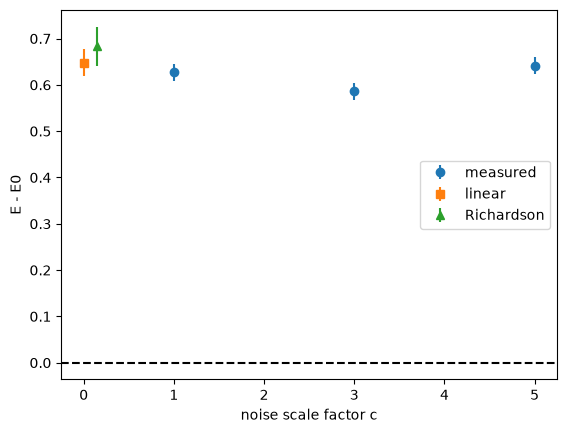

In [11]:
# ZNE of the energy on the model of Garnet. This cell contains two conceptual mistakes.
shots = 10_000
scale_factors = [1, 3, 5]


def fold(circuit, scale_factor):
    """The circuit U folded into U (U^dagger U)^k, with scale_factor = 2k + 1."""
    folded = circuit.copy()
    for _ in range((scale_factor - 1) // 2):
        folded.compose(circuit.inverse(), inplace=True)
        folded.compose(circuit, inplace=True)
    return folded


native = transpile(state_circuit, basis_gates=["r", "cz"], optimization_level=1)   # step 1
energies, standard_errors = [], []
for c in scale_factors:
    # Folding scales all the noise of the circuit, readout errors included, so the extrapolation
    # to c = 0 removes the readout errors too: they need no mitigation of their own.
    energy, error = garnet_energy(fold(native, c), shots, chain, mitigate_readout=False)
    energies.append(energy)
    standard_errors.append(error)

E1, E3, E5 = energies
s1, s3, s5 = standard_errors
linear = (3 * E1 - E3) / 2                                   # through c = 1, 3
linear_error = np.sqrt((3 / 2 * s1)**2 + (1 / 2 * s3)**2)
richardson = (15 * E1 - 10 * E3 + 3 * E5) / 8               # through c = 1, 3, 5
richardson_error = np.sqrt((15 / 8 * s1)**2 + (10 / 8 * s3)**2 + (3 / 8 * s5)**2)

for c, energy, error in zip(scale_factors, energies, standard_errors):
    print("c =", c, "                   E - E0 =", round(energy - E0, 3), "±", round(error, 3))
print("linear (c = 1, 3):        E - E0 =", round(linear - E0, 3), "±", round(linear_error, 3))
print("Richardson (c = 1, 3, 5): E - E0 =", round(richardson - E0, 3), "±", round(richardson_error, 3))

plt.errorbar(scale_factors, np.array(energies) - E0, yerr=standard_errors, fmt="o", label="measured")
plt.errorbar([0], [linear - E0], yerr=[linear_error], fmt="s", label="linear")
plt.errorbar([0.15], [richardson - E0], yerr=[richardson_error], fmt="^", label="Richardson")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("noise scale factor c")
plt.ylabel("E - E0")
plt.legend()
plt.show()

**Report.**

1. *Scaling the noise.* The energy does not rise with the scale factor: at $c = 1$, 3 and 5, the
   energies differ only by shot noise. Even when the circuit runs five times, Garnet's gate errors
   hardly change its energy.
2. *Extrapolation.* The two models agree with each other and with the energy at $c = 1$, so the
   extrapolation is reliable (step 5 of ["Implementing ZNE"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-zne-steps)).
   The bias of about 0.6 therefore does not come from the gates, and ZNE cannot reduce it on this
   device.

<!-- BEGIN SOLUTION -->
**Solution.** (a) The two mistakes:

1. *Folding without barriers.* `fold` builds $U(U^\dagger U)^k$ correctly, but `garnet_energy`
   compiles the folded circuit again, and the compiler recognises each $U^\dagger U$ as the
   identity and removes it (step 2 of ["Implementing ZNE"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-zne-steps)).
   Every scale factor therefore runs the same circuit, with 18 CZs, and gives the same energy: the
   noise was never scaled, so the extrapolation returns the energy at $c = 1$. To see it, compile a
   folded circuit as `garnet_energy` does,
   `transpile(fold(native, 3), backend=garnet, optimization_level=1, initial_layout=chain)`, and
   count its CZs. The fix: `folded.barrier()` before each `compose`. The compiler does not simplify across barriers, so
   the folded circuits keep 18, 54 and 90 CZs.
2. *Readout errors are not scaled.* Folding repeats the gates, not the measurements: each shot is
   read once at every $c$, so the readout errors are the same at every scale factor, and the
   extrapolation keeps their bias, about 0.27 (A3; notes, section
   ["Scaling the noise by folding"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-folding), assumption 1). The comment in the loop
   is wrong. The fix: `mitigate_readout=True`.

With only the first fix, the energies rise with $c$, but both models still end about 0.3 above
$E_0$: this is the readout bias.

(b) After both fixes (cell below), a corrected report: with the readout errors mitigated, the
energies at $c = 1$, 3 and 5 are about 0.36, 0.96 and 1.43 above $E_0$, with 18, 54 and 90 CZs, so
folding scales the gate noise as intended. The linear model ends about 0.06 above $E_0$ and
Richardson about 0.01, so ZNE removes most of the bias of 0.36. The price is the standard error:
0.02 at $c = 1$, but about 0.03 for the linear model and 0.05 for Richardson, larger by the factors
1.6 and 2.3 of the notes (with the same shots at each $c$). The two models agree within their
standard errors; the linear one keeps a small bias of second order in the noise (notes, exercise
["Two-point extrapolation"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#exr-zne-two-points)). Richardson's estimate can fall below
$E_0$, as in the notes' example: this is amplified shot noise, not a better state.

The pattern is that of the notes' example, where the depolarising model gives 0.277, 0.759 and
1.164 at $c = 1$, 3 and 5, and 0.036 (linear) and 0.008 (Richardson) after extrapolation. Garnet's
noise is stronger, so the energies rise faster with $c$, and the extrapolations are a little
further from $E_0$.
<!-- END SOLUTION -->

c = 1 : CZs on Garnet: 18


c = 3 : CZs on Garnet: 54
c = 5 : CZs on Garnet: 90


c = 1                    E - E0 = 0.359 ± 0.02
c = 3                    E - E0 = 0.963 ± 0.022
c = 5                    E - E0 = 1.427 ± 0.022
linear (c = 1, 3):        E - E0 = 0.058 ± 0.032
Richardson (c = 1, 3, 5): E - E0 = 0.006 ± 0.047


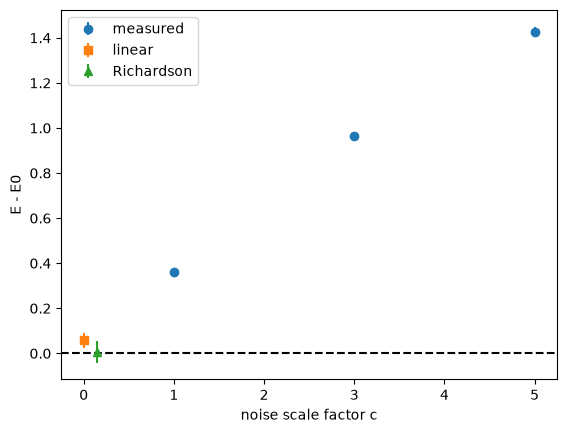

In [12]:
# Your corrected version of the cell above
# BEGIN SOLUTION
def fold(circuit, scale_factor):
    """The circuit U folded into U (U^dagger U)^k, with scale_factor = 2k + 1."""
    folded = circuit.copy()
    for _ in range((scale_factor - 1) // 2):
        folded.barrier()                         # Fix 1: the compiler does not simplify across barriers
        folded.compose(circuit.inverse(), inplace=True)
        folded.barrier()
        folded.compose(circuit, inplace=True)
    return folded


energies, standard_errors = [], []
for c in scale_factors:
    compiled = transpile(fold(native, c), backend=garnet, optimization_level=1, initial_layout=chain)
    print("c =", c, ": CZs on Garnet:", compiled.count_ops()["cz"])      # 18 c: nothing removed, no SWAPs
    # Fix 2: folding does not scale the readout errors, so we mitigate them separately
    energy, error = garnet_energy(fold(native, c), shots, chain, mitigate_readout=True)
    energies.append(energy)
    standard_errors.append(error)

E1, E3, E5 = energies
s1, s3, s5 = standard_errors
linear = (3 * E1 - E3) / 2                                   # through c = 1, 3
linear_error = np.sqrt((3 / 2 * s1)**2 + (1 / 2 * s3)**2)
richardson = (15 * E1 - 10 * E3 + 3 * E5) / 8               # through c = 1, 3, 5
richardson_error = np.sqrt((15 / 8 * s1)**2 + (10 / 8 * s3)**2 + (3 / 8 * s5)**2)

for c, energy, error in zip(scale_factors, energies, standard_errors):
    print("c =", c, "                   E - E0 =", round(energy - E0, 3), "±", round(error, 3))
print("linear (c = 1, 3):        E - E0 =", round(linear - E0, 3), "±", round(linear_error, 3))
print("Richardson (c = 1, 3, 5): E - E0 =", round(richardson - E0, 3), "±", round(richardson_error, 3))

plt.errorbar(scale_factors, np.array(energies) - E0, yerr=standard_errors, fmt="o", label="measured")
plt.errorbar([0], [linear - E0], yerr=[linear_error], fmt="s", label="linear")
plt.errorbar([0.15], [richardson - E0], yerr=[richardson_error], fmt="^", label="Richardson")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("noise scale factor c")
plt.ylabel("E - E0")
plt.legend()
plt.show()
# END SOLUTION

### Exercise 2: symmetry verification

In Lecture 3, a flipped qubit spread through a Heisenberg chain as a light cone. In Lecture 5,
noise blurred the cone, and post-selection on the number of flipped qubits brought it back (notes,
figure ["The light cone with noise"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#fig-light-cone-noise)). Here we repeat this on Garnet,
with fewer qubits and steps than the notes, so that enough shots pass the check: 7 qubits, the
middle one flipped at the start, and up to 5 Trotter steps of length 0.2, on a chain of 7 coupled
qubits. We compile with `optimization_level=2`, which merges the three rotations of a bond gate
and compiles them with 3 CZs instead of 6, so each step has 18 CZs. The first cell defines the
circuits, with `heisenberg_step` from Tutorial 3, Exercise 4; the second defines a function that
plots the light cones. Both are correct.

The third cell runs the circuits and post-selects their shots, following the steps of the notes
(section ["Implementing symmetry verification"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-sv-steps)). The function
`flip_probabilities` estimates the probability of reading 1 on each qubit, with its standard
error; with `post_select=True`, it uses only the shots that pass the symmetry check. The report
after the cell draws conclusions from the output. Both mistakes are in `flip_probabilities`: one in
the shots it keeps, and one in the standard errors it returns.

**Your task.** (a) Find each mistake, and explain in one or two sentences why it is wrong. (b) Fix
the code (in the empty cell after the report, starting from a copy of the third cell), run it, and
rewrite the report. Compare your result with the figure of the notes.

In [13]:
# The problem, defined again so that this exercise stands alone
def heisenberg_step(n_qubits, J, dt):
    """One Trotter step of length dt for the Heisenberg chain on n_qubits qubits (Tutorial 3, Exercise 4)."""
    step = QuantumCircuit(n_qubits)
    for first in [0, 1]:                      # bonds (0,1), (2,3), ..., then (1,2), (3,4), ...
        for i in range(first, n_qubits - 1, 2):
            step.rxx(2 * J * dt, i, i + 1)
            step.ryy(2 * J * dt, i, i + 1)
            step.rzz(2 * J * dt, i, i + 1)
    return step


def light_cone_circuit(n_qubits, J, dt, steps):
    """The middle qubit flipped, then `steps` Trotter steps of length dt."""
    circuit = QuantumCircuit(n_qubits)
    circuit.x(n_qubits // 2)
    for _ in range(steps):
        circuit.compose(heisenberg_step(n_qubits, J, dt), inplace=True)
    return circuit


n_qubits, dt, n_steps = 7, 0.2, 5
chain = [4, 9, 8, 7, 12, 13, 17]          # QB5, QB10, QB9, QB8, QB13, QB14, QB18: a chain of coupled qubits
shots = 4000

In [14]:
from matplotlib.colors import LogNorm      # a logarithmic colour scale, as in Tutorial 3


def plot_light_cones(ideal, noisy, post_selected, kept):
    """The probability of a flip on each qubit against time (without noise, on Garnet, and on Garnet
    with post-selection), and the fraction of shots kept."""
    times = dt * np.arange(n_steps + 1)
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
    titles = ["no noise", "Garnet", "Garnet, post-selected"]
    for ax, data, title in zip(axes[:3], [ideal, noisy, post_selected], titles):
        mesh = ax.pcolormesh(times, range(n_qubits), np.maximum(data, 1e-3).T, shading="nearest",
                             norm=LogNorm(vmin=1e-3, vmax=1))
        ax.set_ylim(n_qubits - 0.5, -0.5)   # qubit 0 at the top, as in a circuit drawing
        ax.set_xlabel("time t")
        ax.set_title(title)
    axes[0].set_ylabel("qubit i")
    fig.colorbar(mesh, ax=axes[:3], label="probability of a flip")
    axes[3].plot(times, kept, "o-")
    axes[3].set_ylim(0, 1)
    axes[3].set_xlabel("time t")
    axes[3].set_title("fraction of shots kept")
    plt.show()

time t:                               [0.  0.2 0.4 0.6 0.8 1. ]
fraction of shots kept:               [0.85 0.77 0.71 0.68 0.64 0.6 ]
flipped qubits per shot, noisy:       [1.12 1.23 1.37 1.45 1.63 1.73]
flipped qubits per kept shot:         [1.02 1.1  1.21 1.3  1.43 1.56]
mean |error|, noisy:                  [0.024 0.037 0.053 0.065 0.09  0.104]
mean |error|, post-selected:          [0.004 0.014 0.03  0.043 0.064 0.081]
middle qubit at t = 1.0 : noisy 0.265 ± 0.007   post-selected 0.23 ± 0.0067   no noise 0.15


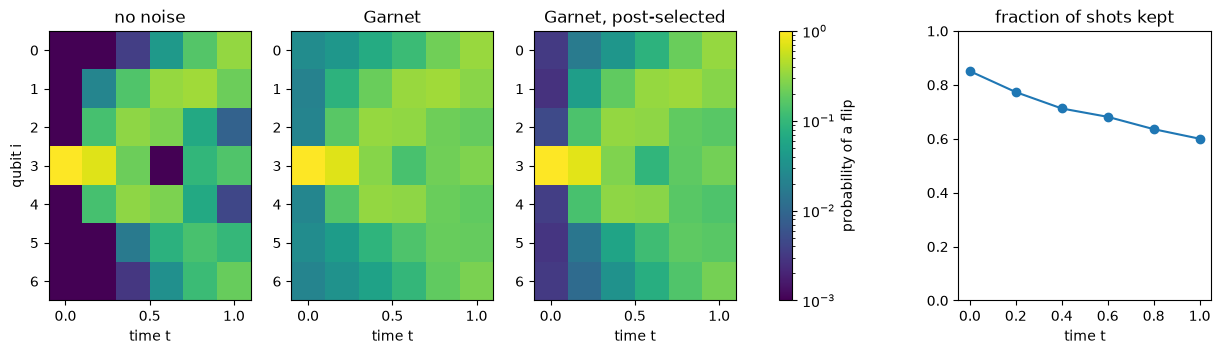

In [15]:
# Symmetry verification of the light cone on Garnet. This cell contains two conceptual mistakes.

def flip_probabilities(counts, post_select):
    """The probability of reading 1 on each qubit, its standard error, and the fraction of shots used.

    With post_select=True, only the shots that pass the symmetry check are used."""
    ones = np.zeros(n_qubits)          # for each qubit, the number of used shots that read 1
    used, total = 0, 0
    for bitstring, count in counts.items():
        bits = [int(b) for b in bitstring[::-1]]      # bits[q] is the bit of qubit q (Qiskit writes qubit 0 last)
        total += count
        keep = True
        if post_select:
            # The check: every gate conserves the number of flipped qubits, and so its parity. At the
            # start it is odd (one flipped qubit), so we keep the shot if it is still odd.
            keep = sum(bits) % 2 == 1
        if keep:
            ones += count * np.array(bits)
            used += count
    probabilities = ones / used
    standard_errors = np.sqrt(probabilities * (1 - probabilities) / total)
    return probabilities, standard_errors, used / total


ideal, noisy, post_selected = [], [], []                # one row per time: a probability per qubit
noisy_errors, post_selected_errors, kept = [], [], []
for k in range(n_steps + 1):
    circuit = light_cone_circuit(n_qubits, J, dt, k)
    state = Statevector(circuit)                       # without noise, for comparison
    ideal.append([state.probabilities([i])[1] for i in range(n_qubits)])
    circuit.measure_all()
    native = transpile(circuit, backend=garnet, optimization_level=2, initial_layout=chain)   # 3 CZs per bond gate
    counts = garnet.run(native, shots=shots).result().get_counts()
    probabilities, errors, fraction = flip_probabilities(counts, post_select=False)
    noisy.append(probabilities)
    noisy_errors.append(errors)
    probabilities, errors, fraction = flip_probabilities(counts, post_select=True)
    post_selected.append(probabilities)
    post_selected_errors.append(errors)
    kept.append(fraction)
ideal, noisy, post_selected = np.array(ideal), np.array(noisy), np.array(post_selected)
noisy_errors, post_selected_errors = np.array(noisy_errors), np.array(post_selected_errors)

print("time t:                              ", dt * np.arange(n_steps + 1))
print("fraction of shots kept:              ", np.round(kept, 2))
print("flipped qubits per shot, noisy:      ", np.round(noisy.sum(axis=1), 2))
print("flipped qubits per kept shot:        ", np.round(post_selected.sum(axis=1), 2))
print("mean |error|, noisy:                 ", np.round(np.abs(noisy - ideal).mean(axis=1), 3))
print("mean |error|, post-selected:         ", np.round(np.abs(post_selected - ideal).mean(axis=1), 3))
middle = n_qubits // 2
print("middle qubit at t =", dt * n_steps, ": noisy", round(noisy[-1, middle], 3), "±", round(noisy_errors[-1, middle], 4),
      "  post-selected", round(post_selected[-1, middle], 3), "±", round(post_selected_errors[-1, middle], 4),
      "  no noise", round(ideal[-1, middle], 3))
plot_light_cones(ideal, noisy, post_selected, kept)

**Report.**

1. *The check.* Every gate conserves the number of flipped qubits, and post-selection keeps the
   shots in which its parity is that of the initial state. It therefore discards every shot in
   which an error changed the number of flipped qubits. What it cannot catch are errors that leave
   this number unchanged, such as $Z$ errors, and these explain the error that remains after
   post-selection.
2. *The price.* Post-selection discards a growing fraction of the shots, but its estimates are as
   precise as the noisy ones: on the middle qubit at $t = 1$, for example, both standard errors
   are about 0.007. Post-selection therefore reduces the bias at no cost in shots.

<!-- BEGIN SOLUTION -->
**Solution.** (a) The two mistakes:

1. *The check is too weak.* The parity is conserved, but it only tells odd from even: a shot with
   3 or 5 flipped qubits passes, although every noiseless shot has exactly one. Such shots come
   from errors that change the number of flips by 2, such as a two-qubit error after a CZ, or two
   readout errors. The printout shows it: the kept shots have up to about 1.5 flipped qubits on
   average, and post-selection reduces the error only a little. The number of flipped qubits can be read
   from the same bits, and it is a stronger check: it keeps one sector of 7 states out of 128,
   while the parity keeps 64 (notes, section
   ["Symmetry verification"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-symmetry-verification), and exercise
   ["Strong and weak symmetries"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#exr-strong-weak)). The fix: `keep = sum(bits) == 1`.
2. *The standard errors use all the shots.* A post-selected probability is estimated from the kept
   shots only, so its standard error is $\sqrt{p(1-p)/N_{\text{kept}}}$, with
   $N_{\text{kept}}$ = `used` in place of $N$ = `total` (step 4 of
   ["Implementing symmetry verification"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#sec-sv-steps)). For the same
   $p$, it is larger by $1/\sqrt{p_{\text{keep}}}$. The fix: divide by `used`. (Comparing
   the standard errors of two different estimates does not show the mistake well: a probability
   close to 0 or 1 has a small standard error, and post-selection moves the probabilities outside
   the cone close to 0.)

(b) After both fixes (cell below), a corrected report: every kept shot has exactly one flipped
qubit. The fraction kept falls from 0.84 at $t = 0$, where only readout errors act, to about 0.46 at
$t = 1$, after 90 CZs. The value at $t = 0$ is the one predicted by the notes' exercise
["Post-selection against readout errors"](https://stefanopolla.github.io/course-testing/L5-mitigation.html#exr-post-selection),
$(1-e)^7 + 6e^2(1-e)^5 \approx 0.84$ for $e = 2.5\%$.
Post-selection reduces the mean error of the probabilities from about 0.10 to 0.03 at $t = 1$, and
the post-selected cone looks like the noiseless one, as in the notes' figure. What remains comes
from errors that post-selection cannot detect, such as $Z$ errors, which change the phases and so
the later spreading, but not the number of flips. The price: at $t = 1$, the post-selected
probabilities come from fewer than half of the shots, so for the same probability their standard
errors are larger by $1/\sqrt{0.46} \approx 1.5$, and their variance by about 2.2: to reach the
standard error of an estimate from all 4000 shots, we would need about twice as many shots. On the
middle qubit, the standard error grows from about 0.007 to 0.008, although the probability falls
from about 0.26 to 0.15, which alone would make it smaller.

In the notes, the depolarising model and 11 qubits gave a fraction kept of 0.90 at $t = 0$ and 0.23
at $t = 2$ (300 CZs), with the mean error falling from 0.14 to 0.02.
<!-- END SOLUTION -->

time t:                               [0.  0.2 0.4 0.6 0.8 1. ]
fraction of shots kept:               [0.85 0.72 0.63 0.57 0.5  0.47]
flipped qubits per shot, noisy:       [1.11 1.27 1.38 1.5  1.62 1.69]
flipped qubits per kept shot:         [1. 1. 1. 1. 1. 1.]
mean |error|, noisy:                  [0.024 0.043 0.054 0.071 0.09  0.099]
mean |error|, post-selected:          [0.001 0.005 0.006 0.013 0.031 0.028]
middle qubit at t = 1.0 : noisy 0.259 ± 0.0069   post-selected 0.158 ± 0.0084   no noise 0.15


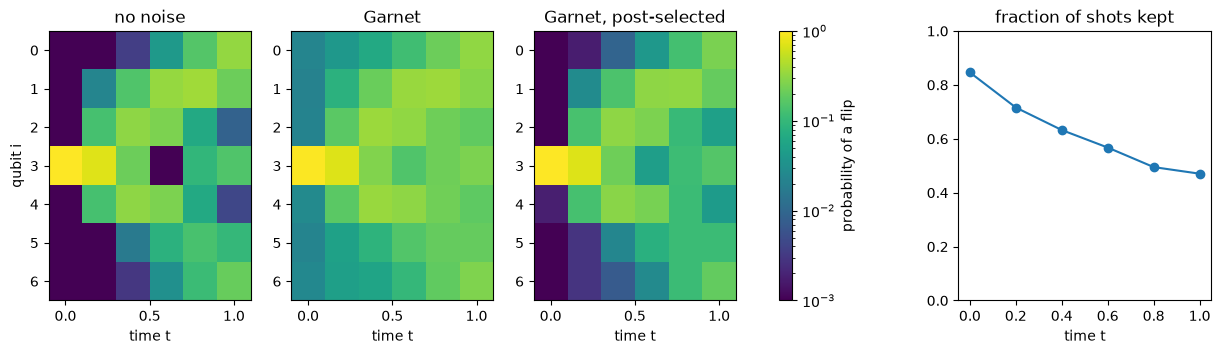

In [16]:
# Your corrected version of the cell above
# BEGIN SOLUTION
def flip_probabilities(counts, post_select):
    """The probability of reading 1 on each qubit, its standard error, and the fraction of shots used.

    With post_select=True, only the shots that pass the symmetry check are used."""
    ones = np.zeros(n_qubits)          # for each qubit, the number of used shots that read 1
    used, total = 0, 0
    for bitstring, count in counts.items():
        bits = [int(b) for b in bitstring[::-1]]      # bits[q] is the bit of qubit q (Qiskit writes qubit 0 last)
        total += count
        keep = True
        if post_select:
            # Fix 1: the number of flipped qubits itself, read from the same bits: exactly one
            keep = sum(bits) == 1
        if keep:
            ones += count * np.array(bits)
            used += count
    probabilities = ones / used
    # Fix 2: the post-selected probabilities come from the `used` shots only
    standard_errors = np.sqrt(probabilities * (1 - probabilities) / used)
    return probabilities, standard_errors, used / total


ideal, noisy, post_selected = [], [], []                # one row per time: a probability per qubit
noisy_errors, post_selected_errors, kept = [], [], []
for k in range(n_steps + 1):
    circuit = light_cone_circuit(n_qubits, J, dt, k)
    state = Statevector(circuit)                       # without noise, for comparison
    ideal.append([state.probabilities([i])[1] for i in range(n_qubits)])
    circuit.measure_all()
    native = transpile(circuit, backend=garnet, optimization_level=2, initial_layout=chain)   # 3 CZs per bond gate
    counts = garnet.run(native, shots=shots).result().get_counts()
    probabilities, errors, fraction = flip_probabilities(counts, post_select=False)
    noisy.append(probabilities)
    noisy_errors.append(errors)
    probabilities, errors, fraction = flip_probabilities(counts, post_select=True)
    post_selected.append(probabilities)
    post_selected_errors.append(errors)
    kept.append(fraction)
ideal, noisy, post_selected = np.array(ideal), np.array(noisy), np.array(post_selected)
noisy_errors, post_selected_errors = np.array(noisy_errors), np.array(post_selected_errors)

print("time t:                              ", dt * np.arange(n_steps + 1))
print("fraction of shots kept:              ", np.round(kept, 2))
print("flipped qubits per shot, noisy:      ", np.round(noisy.sum(axis=1), 2))
print("flipped qubits per kept shot:        ", np.round(post_selected.sum(axis=1), 2))
print("mean |error|, noisy:                 ", np.round(np.abs(noisy - ideal).mean(axis=1), 3))
print("mean |error|, post-selected:         ", np.round(np.abs(post_selected - ideal).mean(axis=1), 3))
middle = n_qubits // 2
print("middle qubit at t =", dt * n_steps, ": noisy", round(noisy[-1, middle], 3), "±", round(noisy_errors[-1, middle], 4),
      "  post-selected", round(post_selected[-1, middle], 3), "±", round(post_selected_errors[-1, middle], 4),
      "  no noise", round(ideal[-1, middle], 3))
plot_light_cones(ideal, noisy, post_selected, kept)
# END SOLUTION

## Wrap-up

- A backend such as `IQMFakeGarnet()` compiles and runs circuits as a device does:
  `transpile(circuit, backend=garnet, ...)`, then `garnet.run(native, shots=...)`. Fix the layout with
  `initial_layout` to choose the qubits, and count the CZs of the compiled circuit to check that no
  SWAPs were added.
- Readout errors are mitigated on their own, from the calibration data: folding repeats the gates,
  not the measurements.
- Fold the compiled circuit with barriers between its parts, or the compiler removes
  $U^\dagger U$ and the noise is never scaled. ZNE then removes most of the bias, and amplifies the
  shot noise.
- Post-select on the strongest check that the shots can reveal, estimate from the kept shots, and
  compute the standard errors from their number.
- Check a mitigated result against what the method must give: the energy must rise with the scale
  factor, and every kept shot must have the quantum number of the initial state.

Next week, in Tutorial 6, we run circuits on IQM's devices themselves.